In [2]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

In [3]:
external = pd.read_csv("external_sources.csv")

external[["site_url", "type"]].head()

,site_url,type
0,100percentfedup.com,bias
1,100percentfedup.com,bias
2,100percentfedup.com,bias
3,100percentfedup.com,bias
4,100percentfedup.com,bias


In [4]:
network_data = external[["site_url", "type"]].copy()

network_data = network_data.dropna(subset=["site_url", "type"])

network_data["site_url"] = (
    network_data["site_url"]
    .str.lower()
    .str.replace(r"^https?://", "", regex=True)
    .str.replace(r"^www\.", "", regex=True)
    .str.split("/")
    .str[0]
)

network_data = network_data.drop_duplicates()

network_data.head()

,site_url,type
0,100percentfedup.com,bias
33,21stcenturywire.com,conspiracy
57,abcnews.com.co,fake
59,abeldanger.net,bs
159,abovetopsecret.com,bs


In [5]:
# Create the network
G = nx.Graph()

edges = list(zip(network_data["site_url"], network_data["type"]))

G.add_edges_from(edges)

print("Number of nodes:", G.number_of_nodes())
print("Number of connections:", G.number_of_edges())

Number of nodes: 252
Number of connections: 244


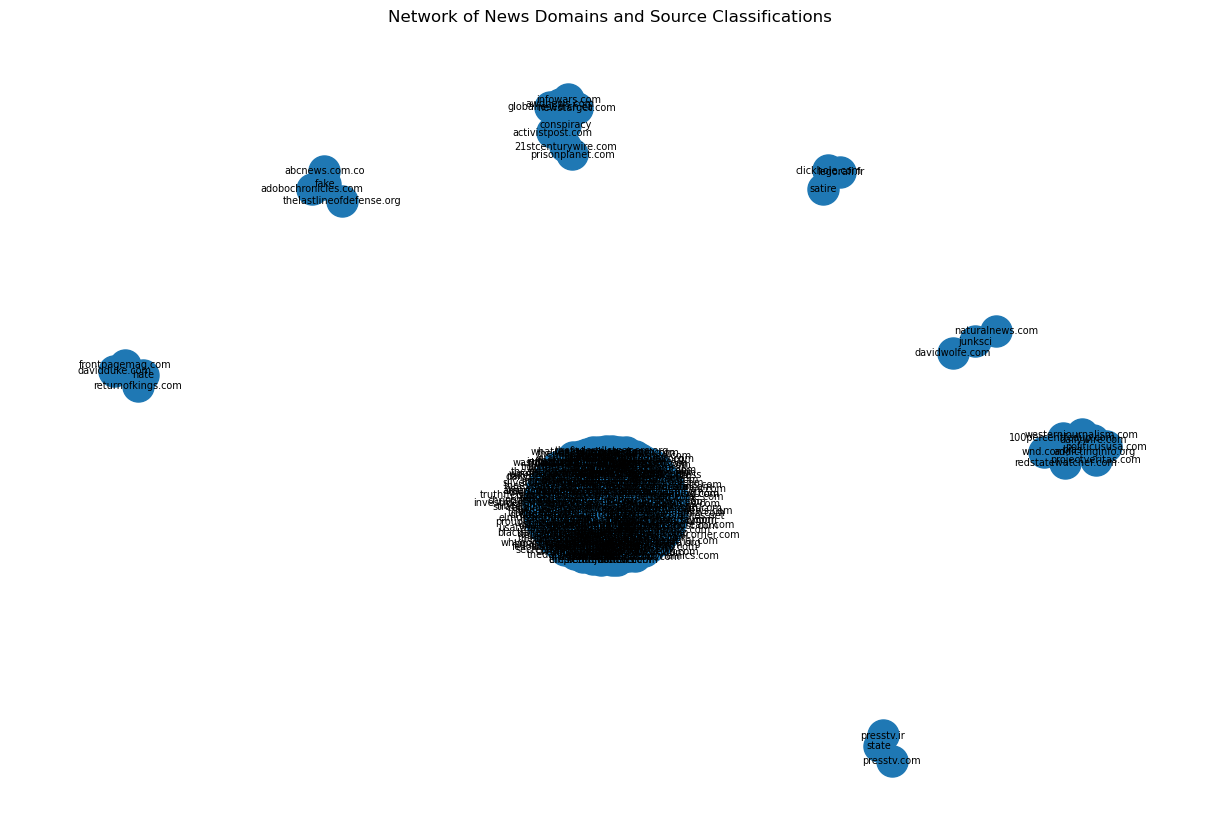

In [6]:
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=500,
    font_size=7
)

plt.title("Network of News Domains and Source Classifications")
plt.show()

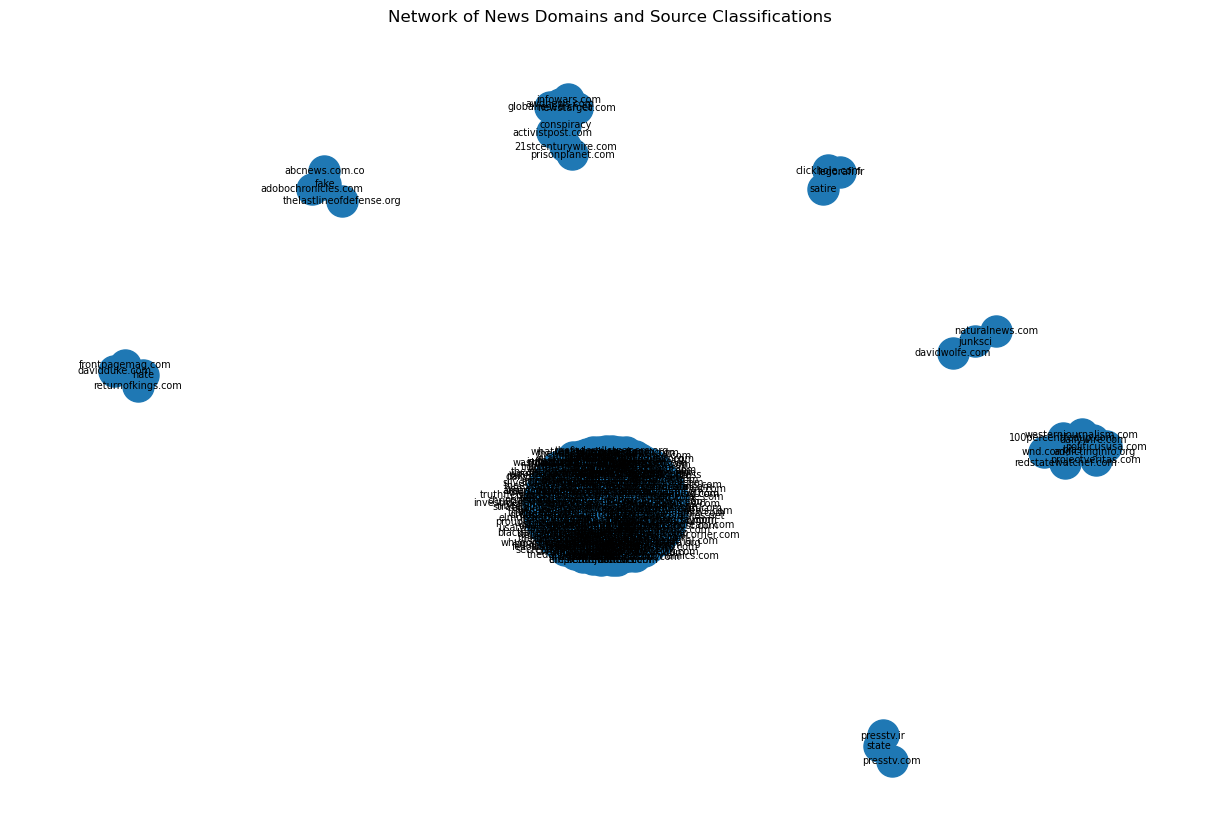

In [7]:
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, seed=42)

nx.draw(G, pos, with_labels=True, node_size=500, font_size=7)

plt.title("Network of News Domains and Source Classifications")
plt.show()

In [8]:
# Analyse the most connected domains
domain_connections = pd.Series(
    dict(G.degree())
).sort_values(ascending=False)

domain_connections.head(15)

bs                    217
bias                    8
conspiracy              7
fake                    3
hate                    3
satire                  2
junksci                 2
state                   2
russia-insider.com      1
satirewire.com          1
russia-direct.org       1
sgtreport.com           1
shadowproof.com         1
shiftfrequency.com      1
shtfplan.com            1
dtype: int64

In [9]:
domain_connections = domain_connections[
    domain_connections.index.isin(network_data["site_url"])
]

domain_connections.head(15)

russia-insider.com     1
satirewire.com         1
russia-direct.org      1
sgtreport.com          1
shadowproof.com        1
shiftfrequency.com     1
shtfplan.com           1
silverdoctors.com      1
sott.net               1
rumormillnews.com      1
southfront.org         1
spinzon.com            1
secretsofthefed.com    1
100percentfedup.com    1
sputniknews.com        1
dtype: int64

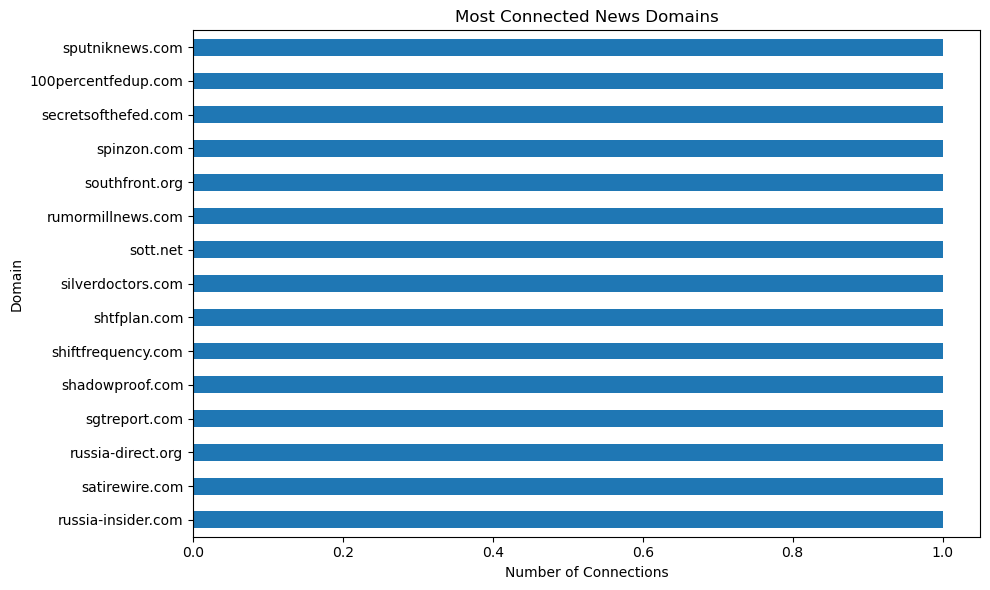

In [10]:
# Visualise the top 15 domains
top_domains = domain_connections.head(15)

top_domains.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Most Connected News Domains")
plt.xlabel("Number of Connections")
plt.ylabel("Domain")
plt.tight_layout()
plt.show()